In [75]:
import pandas as pd

# Sæt python kernel på git niveau

In [76]:
import os, subprocess

try:
    root = subprocess.check_output(
        ["git", "rev-parse", "--show-toplevel"],
        stderr=subprocess.DEVNULL, text=True,
    ).strip()
    os.chdir(root)
except Exception:
    pass  # not in a git repo, leave the CWD alone

# Load indkomst data ind for kvinder

In [95]:
path = "data/raw/indkomst/kvinder.csv"
df_income_women = pd.read_csv(path, encoding="latin-1")

In [96]:
df_income_women.columns

Index([' ', ' .1', ' .2', ' .3', '2020', '2021', '2022', '2023', '2024',
       '2025'],
      dtype='str')

In [97]:

df_income_women = df_income_women.drop([' ', ' .1', ' .2'], axis=1)
df_income_women.rename(columns={' .3': 'Område'}, inplace=True)

In [ ]:
df_income_women

,Område,2020,2021,2022,2023,2024,2025
0,Landsdel Byen Kï¿½benhavn,326429,334092,345371,362011,383113,400122
1,Kï¿½benhavn,317276,326546,338505,355243,375813,392874
2,Frederiksberg,367846,369218,378625,394478,417747,436291
3,Dragï¿½r,404611,406891,418295,436534,458917,480464
4,Tï¿½rnby,345855,345135,351319,367955,393202,403656
...,...,...,...,...,...,...,...
104,Morsï¿½,264963,266330,270847,279897,289962,310320
105,Rebild,311722,314714,319527,329251,345147,362469
106,Thisted,263313,263386,267682,278984,292786,309520
107,Vesthimmerlands,278202,279356,284013,292554,303665,320478


# Load indkomst data ind for mænd

In [102]:
path = "data/raw/indkomst/mænd.csv"
df_income_men = pd.read_csv(path, encoding="latin-1")

In [103]:
df_income_men.columns

Index([' ', ' .1', ' .2', ' .3', '2020', '2021', '2022', '2023', '2024',
       '2025'],
      dtype='str')

In [104]:

df_income_men = df_income_men.drop([' ', ' .1', ' .2'], axis=1)
df_income_men.rename(columns={' .3': 'Område'}, inplace=True)
df_income_men

,Område,2020,2021,2022,2023,2024,2025
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Landsdel Byen Kï¿½benhavn,415306.0,423726.0,438224.0,455113.0,478814.0,500588.0
2,Kï¿½benhavn,402367.0,411454.0,426447.0,444476.0,467123.0,488258.0
3,Frederiksberg,483678.0,492747.0,505246.0,514994.0,548549.0,571100.0
4,Dragï¿½r,546828.0,550206.0,568578.0,579617.0,611274.0,627420.0
...,...,...,...,...,...,...,...
105,Morsï¿½,321507.0,330681.0,337526.0,345908.0,352283.0,379900.0
106,Rebild,399066.0,408093.0,416593.0,432757.0,452143.0,475630.0
107,Thisted,329167.0,336473.0,344521.0,354808.0,366894.0,391918.0
108,Vesthimmerlands,334606.0,344488.0,353683.0,362377.0,374235.0,399872.0


# Import landcover classification

In [84]:
import xarray as xr
file = "data/raw/esa/land_cover_class/C3S-LC-L4-LCCS-Map-300m-P1Y-2021-v2.1.1.area-subset.57.76.15.2.54.56.8.07.nc"

ds = xr.open_dataset(file, engine="netcdf4")
ds


<xarray.Dataset> Size: 36MB
Dimensions:              (time: 1, lat: 1152, lon: 2567, bounds: 2)
Coordinates:
  * time                 (time) datetime64[ns] 8B 2021-01-01
  * lat                  (lat) float64 9kB 57.76 57.76 57.75 ... 54.57 54.56
  * lon                  (lon) float64 21kB 8.071 8.074 8.076 ... 15.2 15.2
Dimensions without coordinates: bounds
Data variables:
    lccs_class           (time, lat, lon) uint8 3MB ...
    processed_flag       (time, lat, lon) float32 12MB ...
    current_pixel_state  (time, lat, lon) float32 12MB ...
    observation_count    (time, lat, lon) uint16 6MB ...
    change_count         (time, lat, lon) uint8 3MB ...
    crs                  int32 4B ...
    lat_bounds           (lat, bounds) float64 18kB ...
    lon_bounds           (lon, bounds) float64 41kB ...
    time_bounds          (time, bounds) datetime64[ns] 16B ...
Attributes: (12/38)
    title:                      Land Cover Map of 2021
    summary:                    This dataset characterizes the land cover of ...
    type:                       C3S-LC-L4-LCCS-Map-300m-P1Y
    references:                 https://cds.climate.copernicus.eu/
    institution:                UCLouvain
    contact:                    copernicus-support@ecmwf.int
    ...                         ...
    geospatial_lon_resolution:  0.002778
    id:                         C3S-LC-L4-LCCS-Map-300m-P1Y-2021-v2.1.1
    project:                    EC C3S Land Cover
    source:                     Sentinel-3 OLCI
    geospatial_lon_min:         -180.0
    geospatial_lon_max:         180.0

In [85]:
df_landcover_class = ds.to_dataframe().reset_index()

In [86]:
import numpy as np

attrs = ds["lccs_class"].attrs

values = np.asarray(attrs["flag_values"])          # [0, 10, 11, 12, 20, ...]
meanings = attrs["flag_meanings"].split()          # ['no_data', 'cropland_rainfed', ...]
colors = attrs["flag_colors"].split()              # ['#ffff64', ...] (37 entries)

code_to_label = dict(zip(values, meanings))
code_to_color = dict(zip(values[1:], colors))      # skip code 0, which has no color

In [87]:
df_landcover_class

,time,lat,lon,bounds,lccs_class,processed_flag,current_pixel_state,observation_count,change_count,crs,lat_bounds,lon_bounds,time_bounds
0,2021-01-01,57.759722,8.070833,0,210,1.0,2.0,284,0,-2147483647,57.761111,8.069444,2021-01-01
1,2021-01-01,57.759722,8.070833,1,210,1.0,2.0,284,0,-2147483647,57.758333,8.072222,2021-12-31
2,2021-01-01,57.759722,8.073611,0,210,1.0,2.0,284,0,-2147483647,57.761111,8.072222,2021-01-01
3,2021-01-01,57.759722,8.073611,1,210,1.0,2.0,284,0,-2147483647,57.758333,8.075000,2021-12-31
4,2021-01-01,57.759722,8.076389,0,210,1.0,2.0,288,0,-2147483647,57.761111,8.075000,2021-01-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5914363,2021-01-01,54.562500,15.193056,1,210,1.0,2.0,332,0,-2147483647,54.561111,15.194444,2021-12-31
5914364,2021-01-01,54.562500,15.195833,0,210,1.0,2.0,322,0,-2147483647,54.563889,15.194444,2021-01-01
5914365,2021-01-01,54.562500,15.195833,1,210,1.0,2.0,322,0,-2147483647,54.561111,15.197222,2021-12-31
5914366,2021-01-01,54.562500,15.198611,0,210,1.0,2.0,321,0,-2147483647,54.563889,15.197222,2021-01-01


In [88]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

In [89]:
def pivot_to_grid(df, value_col):
    """
    Convert long-format (lon, lat, value) rows into a 2D array
    suitable for imshow, using unique sorted lon/lat as the axes.
    """
    lons = np.sort(df["lon"].unique())
    lats = np.sort(df["lat"].unique())[::-1]  # north at top
 
    lon_idx = {v: i for i, v in enumerate(lons)}
    lat_idx = {v: i for i, v in enumerate(lats)}
 
    grid = np.full((len(lats), len(lons)), np.nan)
 
    rows = df["lat"].map(lat_idx).values
    cols = df["lon"].map(lon_idx).values
    grid[rows, cols] = df[value_col].values
 
    extent = [lons.min(), lons.max(), lats.min(), lats.max()]
    return grid, extent
 

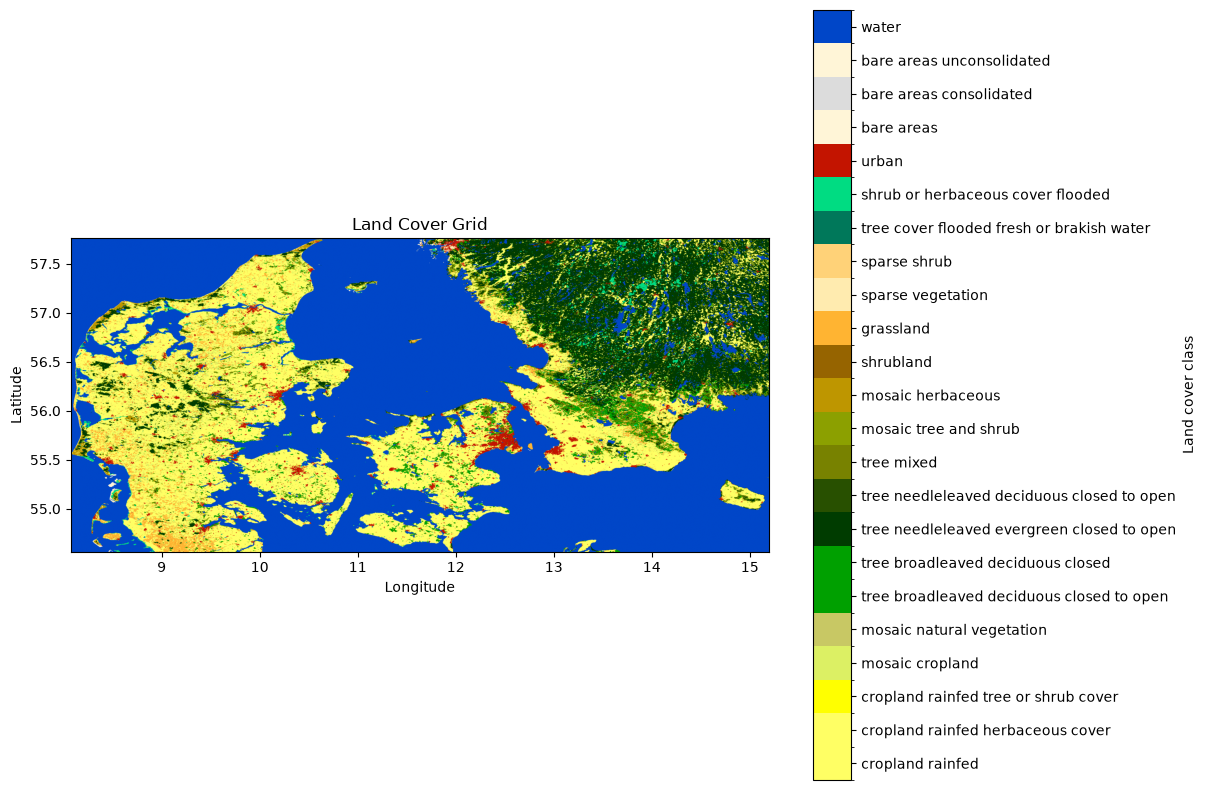

In [90]:
def plot_land_cover(df, attrs):
    grid, extent = pivot_to_grid(df, "lccs_class")

    values = np.asarray(attrs["flag_values"])
    meanings = attrs["flag_meanings"].split()
    colors = attrs["flag_colors"].split()
    code_to_label = dict(zip(values, meanings))
    code_to_color = dict(zip(values[1:], colors))

    codes = sorted(int(c) for c in df["lccs_class"].unique())
    n = len(codes)
    labels = [code_to_label[c].replace("_", " ") for c in codes]
    cmap = ListedColormap([code_to_color.get(c, "#000000") for c in codes])

    # Remap codes to indices 0..n-1
    grid = np.asarray(grid, dtype=float)
    code_arr = np.array(codes)
    idx = np.clip(np.searchsorted(code_arr, grid), 0, n - 1)
    valid = np.isfinite(grid) & (code_arr[idx] == grid)
    grid_idx = np.ma.masked_where(~valid, idx)

    norm = BoundaryNorm(np.arange(n + 1) - 0.5, cmap.N)

    fig, ax = plt.subplots(figsize=(12, 8))
    im = ax.imshow(grid_idx, extent=extent, cmap=cmap, norm=norm, origin="upper")
    cbar = fig.colorbar(im, ax=ax, ticks=np.arange(n))
    cbar.ax.set_yticklabels(labels)
    cbar.set_label("Land cover class")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Land Cover Grid")
    plt.tight_layout()
    plt.show()

# call it with the variable's attrs
plot_land_cover(df, ds["lccs_class"].attrs)

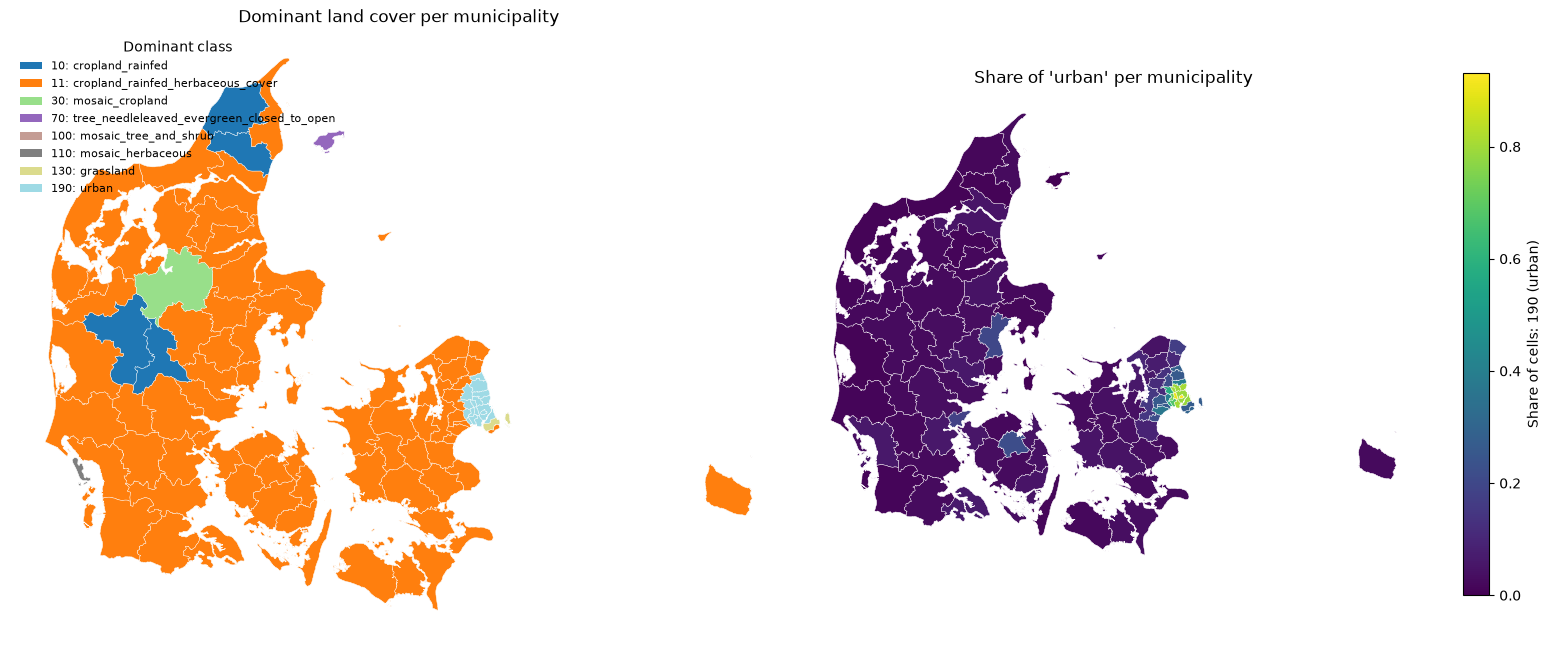

               dominant_class  n_cells  share_selected  \
kommune                                                  
Christiansø               100        7        0.000000   
Frederiksberg             190      159        0.930818   
Vallensbæk                190      165        0.575758   
Herlev                    190      222        0.797297   
Rødovre                   190      228        0.899123   
Glostrup                  190      243        0.720165   
Dragør                     11      353        0.294618   
Brøndby                   190      396        0.679293   
Albertslund               190      426        0.399061   
Hvidovre                  190      427        0.800937   

                                  dominant_label  
kommune                                           
Christiansø                mosaic_tree_and_shrub  
Frederiksberg                              urban  
Vallensbæk                                 urban  
Herlev                                     urban

In [91]:
"""
Map ESA CCI land cover (lcc) per Danish municipality.

Left panel : dominant land cover class per municipality
Right panel: share of one chosen class per municipality (default: urban = 190)

Edit the three paths/settings under CONFIG, then run:  python landcover_map.py
"""
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ---------------------------------------------------------------- CONFIG
NC_FILE = file
GPKG_FILE = "data/raw/kommuner_geodataw/gadm41_DNK.gpkg"
GPKG_LAYER = "ADM_ADM_2"
CLASS_TO_MAP = 190          # class whose share is shown in the right panel (190 = urban)
OUT_PNG = "landcover_map.png"
# Denmark bounding box (lon_min, lon_max, lat_min, lat_max)
BBOX = (8.0, 15.3, 54.5, 57.8)
# -----------------------------------------------------------------------

# 1. Land cover grid -> table of cell centres
ds = xr.open_dataset(NC_FILE)
lcc = ds["lccs_class"].isel(time=0)

lon_min, lon_max, lat_min, lat_max = BBOX
lat_vals = ds["lat"].values
lat_slice = slice(lat_min, lat_max) if lat_vals[0] < lat_vals[-1] else slice(lat_max, lat_min)
lcc = lcc.sel(lat=lat_slice, lon=slice(lon_min, lon_max))

df = lcc.to_dataframe().reset_index()[["lat", "lon", "lccs_class"]].dropna()
df["lccs_class"] = df["lccs_class"].astype(int)

# class code -> readable name, taken from the file itself
flag_values = np.asarray(ds["lccs_class"].attrs["flag_values"]).astype(int)
flag_meanings = ds["lccs_class"].attrs["flag_meanings"].split()
labels = dict(zip(flag_values, flag_meanings))

# 2. Municipalities
muni = gpd.read_file(GPKG_FILE, layer=GPKG_LAYER, engine="pyogrio")
muni = muni[["NAME_2", "geometry"]].rename(columns={"NAME_2": "kommune"})

points = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326"
).to_crs(muni.crs)

# 3. Point-in-polygon join and per-municipality statistics
joined = gpd.sjoin(points, muni, how="inner", predicate="within")
counts = pd.crosstab(joined["kommune"], joined["lccs_class"])
shares = counts.div(counts.sum(axis=1), axis=0)

stats = pd.DataFrame({
    "dominant_class": counts.idxmax(axis=1),
    "n_cells": counts.sum(axis=1),
    "share_selected": shares[CLASS_TO_MAP] if CLASS_TO_MAP in shares else 0.0,
})
stats["dominant_label"] = stats["dominant_class"].map(labels)

muni_stats = muni.merge(stats, left_on="kommune", right_index=True, how="left")
muni_stats = muni_stats.to_crs(25832)   # nicer shape for Denmark than raw lon/lat

# 4. Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

# left: dominant class (categorical)
ax = axes[0]
present = sorted(muni_stats["dominant_class"].dropna().astype(int).unique())
cmap = plt.get_cmap("tab20", max(len(present), 1))
color_of = {c: cmap(i) for i, c in enumerate(present)}

muni_stats.plot(ax=ax, color="lightgrey", edgecolor="white", linewidth=0.3)   # municipalities without data
has_data = muni_stats.dropna(subset=["dominant_class"]).copy()
has_data["color"] = has_data["dominant_class"].astype(int).map(color_of)
has_data.plot(ax=ax, color=has_data["color"], edgecolor="white", linewidth=0.3)
ax.legend(
    handles=[Patch(facecolor=color_of[c], label=f"{c}: {labels.get(c, '?')}") for c in present],
    loc="upper left", fontsize=8, frameon=False, title="Dominant class",
)
ax.set_title("Dominant land cover per municipality")
ax.set_axis_off()

# right: share of selected class (continuous)
ax = axes[1]
muni_stats.plot(
    column="share_selected", ax=ax, cmap="viridis", legend=True,
    edgecolor="white", linewidth=0.3,
    legend_kwds={"label": f"Share of cells: {CLASS_TO_MAP} ({labels.get(CLASS_TO_MAP, '?')})",
                 "shrink": 0.6},
    missing_kwds={"color": "lightgrey"},
)
ax.set_title(f"Share of '{labels.get(CLASS_TO_MAP, CLASS_TO_MAP)}' per municipality")
ax.set_axis_off()

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=200)
plt.show()

# sanity check: municipalities with very few 1 km cells are unreliable
print(stats.sort_values("n_cells").head(10))

lccs_class   10: cropland_rainfed  11: cropland_rainfed_herbaceous_cover  \
kommune                                                                    
Aabenraa                     10.7                                   51.4   
Aalborg                      25.3                                   38.0   
Albertslund                   1.9                                    7.0   
Allerød                      13.8                                   35.4   
Assens                       11.7                                   67.2   

lccs_class   12: cropland_rainfed_tree_or_shrub_cover  30: mosaic_cropland  \
kommune                                                                      
Aabenraa                                          0.0                  9.9   
Aalborg                                           0.0                 10.9   
Albertslund                                       0.0                  6.1   
Allerød                                           0.0                  7.3   

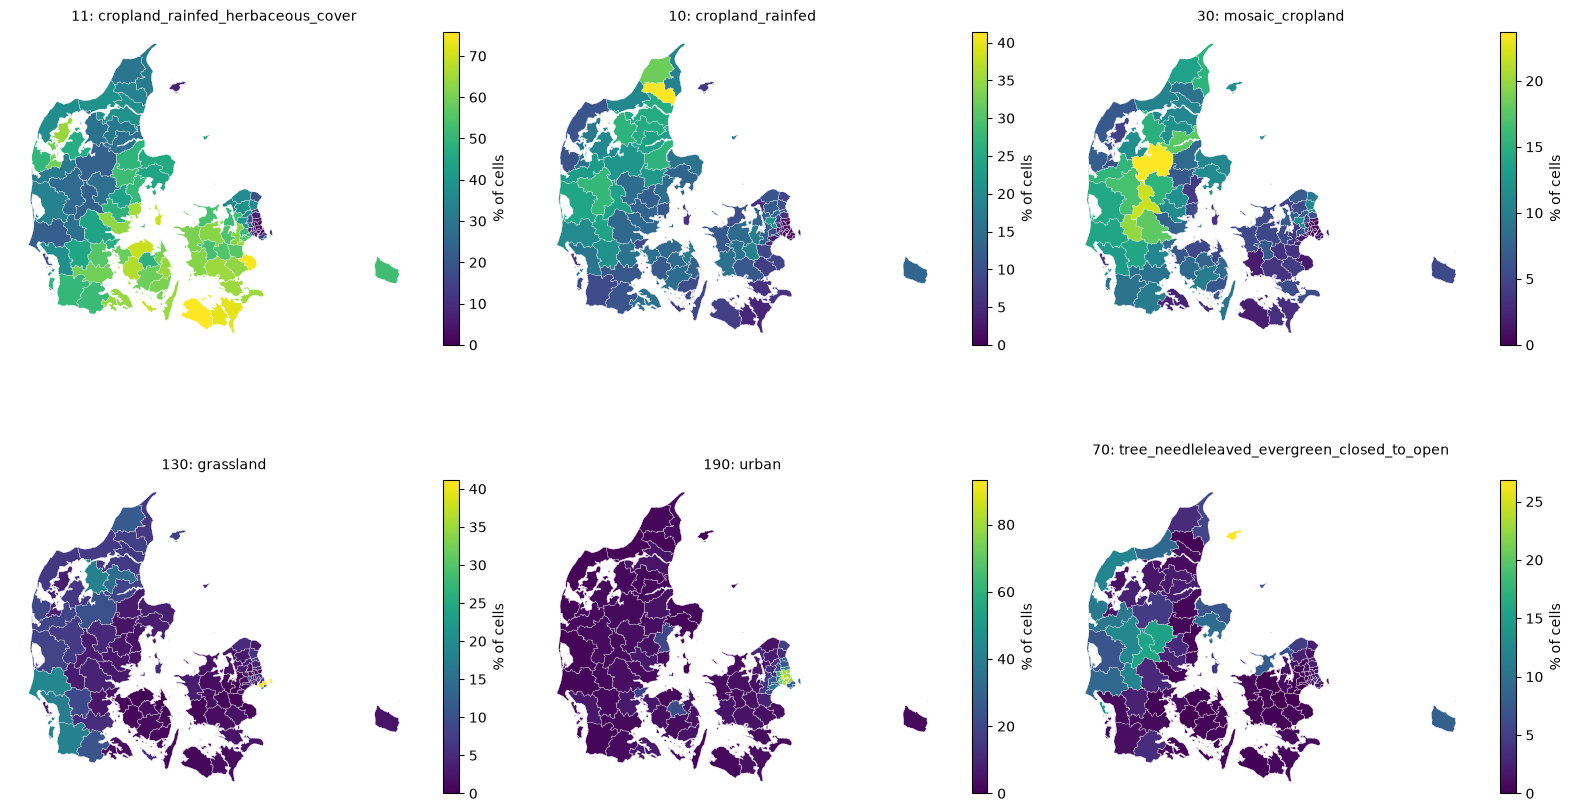

<Figure size 640x480 with 0 Axes>

               dominant_class  n_cells  share_selected  \
kommune                                                  
Christiansø               100        7        0.000000   
Frederiksberg             190      159        0.930818   
Vallensbæk                190      165        0.575758   
Herlev                    190      222        0.797297   
Rødovre                   190      228        0.899123   
Glostrup                  190      243        0.720165   
Dragør                     11      353        0.294618   
Brøndby                   190      396        0.679293   
Albertslund               190      426        0.399061   
Hvidovre                  190      427        0.800937   

                                  dominant_label  
kommune                                           
Christiansø                mosaic_tree_and_shrub  
Frederiksberg                              urban  
Vallensbæk                                 urban  
Herlev                                     urban

In [92]:
"""
Map ESA CCI land cover (lcc) per Danish municipality.

Left panel : dominant land cover class per municipality
Right panel: share of one chosen class per municipality (default: urban = 190)

Edit the three paths/settings under CONFIG, then run:  python landcover_map.py
"""
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ---------------------------------------------------------------- CONFIG
NC_FILE = file
GPKG_FILE = "data/raw/kommuner_geodataw/gadm41_DNK.gpkg"
GPKG_LAYER = "ADM_ADM_2"
CLASS_TO_MAP = 190          # class whose share is shown in the right panel (190 = urban)
OUT_PNG = "landcover_map.png"
# Denmark bounding box (lon_min, lon_max, lat_min, lat_max)
BBOX = (8.0, 15.3, 54.5, 57.8)
# -----------------------------------------------------------------------

# 1. Land cover grid -> table of cell centres
ds = xr.open_dataset(NC_FILE)
lcc = ds["lccs_class"].isel(time=0)

lon_min, lon_max, lat_min, lat_max = BBOX
lat_vals = ds["lat"].values
lat_slice = slice(lat_min, lat_max) if lat_vals[0] < lat_vals[-1] else slice(lat_max, lat_min)
lcc = lcc.sel(lat=lat_slice, lon=slice(lon_min, lon_max))

df = lcc.to_dataframe().reset_index()[["lat", "lon", "lccs_class"]].dropna()
df["lccs_class"] = df["lccs_class"].astype(int)

# class code -> readable name, taken from the file itself
flag_values = np.asarray(ds["lccs_class"].attrs["flag_values"]).astype(int)
flag_meanings = ds["lccs_class"].attrs["flag_meanings"].split()
labels = dict(zip(flag_values, flag_meanings))

# 2. Municipalities
muni = gpd.read_file(GPKG_FILE, layer=GPKG_LAYER, engine="pyogrio")
muni = muni[["NAME_2", "geometry"]].rename(columns={"NAME_2": "kommune"})

points = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df["lon"], df["lat"]), crs="EPSG:4326"
).to_crs(muni.crs)

# 3. Point-in-polygon join and per-municipality statistics
joined = gpd.sjoin(points, muni, how="inner", predicate="within")
counts = pd.crosstab(joined["kommune"], joined["lccs_class"])
shares = counts.div(counts.sum(axis=1), axis=0)

stats = pd.DataFrame({
    "dominant_class": counts.idxmax(axis=1),
    "n_cells": counts.sum(axis=1),
    "share_selected": shares[CLASS_TO_MAP] if CLASS_TO_MAP in shares else 0.0,
})
stats["dominant_label"] = stats["dominant_class"].map(labels)

muni_stats = muni.merge(stats, left_on="kommune", right_index=True, how="left")
muni_stats = muni_stats.to_crs(25832)   # nicer shape for Denmark than raw lon/lat

# 4. Percentage of every class per municipality -> table
pct = (shares * 100).round(1)
pct_named = pct.rename(columns=lambda c: f"{c}: {labels.get(c, '?')}")
pct_named["n_cells"] = counts.sum(axis=1)          # so you can spot unreliable rows
pct_named.to_csv("landcover_share_per_municipality.csv")
print(pct_named.head())

# 5. Map: one panel per class (the N most common classes overall)
N = 6
top = counts.sum().sort_values(ascending=False).head(N).index

map_df = muni.merge(
    pct[top].rename(columns=lambda c: f"class_{c}"),
    left_on="kommune", right_index=True, how="left",
).to_crs(25832)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, c in zip(axes.ravel(), top):
    map_df.plot(
        column=f"class_{c}", ax=ax, cmap="viridis", vmin=0,
        edgecolor="white", linewidth=0.2, legend=True,
        legend_kwds={"shrink": 0.6, "label": "% of cells"},
        missing_kwds={"color": "lightgrey"},
    )
    ax.set_title(f"{c}: {labels.get(c, '?')}", fontsize=10)
    ax.set_axis_off()

plt.tight_layout()
plt.savefig("landcover_shares.png", dpi=200)
plt.show()
ax.set_title(f"Share of '{labels.get(CLASS_TO_MAP, CLASS_TO_MAP)}' per municipality")
ax.set_axis_off()

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=200)
plt.show()

# sanity check: municipalities with very few 1 km cells are unreliable
print(stats.sort_values("n_cells").head(10))

skal fikses.
- Indkomst utf problemer
- har samlet dem i men_women_income, men endnu ikke lagt ind

In [94]:
import numpy as np
from adjustText import adjust_text      # pip install adjustText

# ---- settings
CLASS_X = 190                            # land cover class on the x-axis
INCOME_CSV = "income_per_kommune.csv"    # columns: kommune, income

# ---- data
income = pd.read_csv(INCOME_CSV).set_index("kommune")["income"]

print("Available classes:", {c: labels.get(c) for c in shares.columns})
x = (shares[CLASS_X] * 100).rename("pct_class")

data = pd.concat([x, income], axis=1, join="inner").dropna()

# ---- check that names matched
unmatched = set(x.index) ^ set(income.index)
print("Names that did not match between the two sources:", sorted(unmatched))

# ---- plot
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(data["pct_class"], data["income"], s=40, alpha=0.8)

texts = [ax.text(xv, yv, name, fontsize=7)
         for name, xv, yv in zip(data.index, data["pct_class"], data["income"])]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))

# optional trend line and correlation
k, m = np.polyfit(data["pct_class"], data["income"], 1)
xs = np.linspace(data["pct_class"].min(), data["pct_class"].max(), 100)
ax.plot(xs, k * xs + m, color="grey", ls="--", lw=1)
rho = data["pct_class"].corr(data["income"], method="spearman")

ax.set_xlabel(f"% of cells: {labels.get(CLASS_X, CLASS_X)} (class {CLASS_X})")
ax.set_ylabel("Income")
ax.set_title(f"Income vs. land cover per municipality (Spearman rho = {rho:.2f})")
plt.tight_layout()
plt.savefig("income_vs_landcover.png", dpi=200)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'income_per_kommune.csv'